# Valuation da CSA: concessão de água e esgoto do Amapá
A CSA (Concessionária de Saneamento do Amapá) é a empresa responsável pela concessão de saneamento básico do Amapá, Estado com uma das menores coberturas de água e esgoto do Brasil. A empresa venceu o leilão da concessão em 2021 e assumiu os serviços em julho de 2022, mas tem apresentado desafios na gestão e no cumprimento das metas.

In [26]:
!pip install numpy-financial
import pandas as pd
import numpy as np
import numpy_financial as npf
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

In [27]:
# dados: todos lidos do repositório no GitHub, para o notebook rodar em qualquer computador
URL_DADOS = "https://raw.githubusercontent.com/marialuisagama/valuation-csa/main/dados/"
ARQ_EQTL = URL_DADOS + "equatorial_fundamentos_2T26.xlsx"

op  = pd.read_excel(ARQ_EQTL, sheet_name="Operacional Saneamento", header=6, index_col=1)
dre = pd.read_excel(ARQ_EQTL, sheet_name="DRE CSA", header=7, index_col=0)

## 1. Contexto
Com a intenção de escolher um bom candidato para sugerir um investimento de concessão de saneamento, duas planilhas de dados públicos, SINISA e IBGE, foram combinadas para avaliar as possibilidades. A princípio, foram limitados os dados de população entre 100.000 e 500.000 habitantes e atendimento de coleta de menos de 50% de esgoto. Essas duas faixas filtrariam os candidatos com população expressiva, gerando escala suficiente para atrair uma operadora privada e cobertura com alta necessidade de investimento.

In [28]:
dfsinisa = pd.read_excel(URL_DADOS + "sinisa_esgoto_2024.xlsx", sheet_name=0, header=10)
dfibge = pd.read_excel(URL_DADOS + "ibge_populacao_2026.xlsx", sheet_name=1, header=1)

dfibge = dfibge.dropna(subset=["COD. MUNIC"])
dfibge["cod_IBGE"] = (dfibge["COD. MUNIC"] + (dfibge["COD. UF"] * 100000)).astype(int)
dfsinisa["IES0001"] = pd.to_numeric(dfsinisa["IES0001"], errors="coerce")
juntas = dfsinisa.merge(dfibge[["cod_IBGE", "POPULAÇÃO ESTIMADA"]], on="cod_IBGE", how="left")
candidatos = juntas[(juntas["POPULAÇÃO ESTIMADA"].between(100000, 500000)) & (juntas["IES0001"] < 50)]
candidatos[["Município", "UF", "POPULAÇÃO ESTIMADA", "IES0001", "CAD0002"]].sort_values("POPULAÇÃO ESTIMADA", ascending=False)

,Município,UF,POPULAÇÃO ESTIMADA,IES0001,CAD0002
43,Macapá,AP,491987.0,14.94,Empresa privada
349,Caruaru,PE,408281.0,48.02,Sociedade de economia mista
15,Rio Branco,AC,390058.0,25.07,Autarquia
112,Caucaia,CE,380944.0,42.33,Sociedade de economia mista
1357,Cariacica,ES,376914.0,43.64,Sociedade de economia mista
...,...,...,...,...,...
64,Balsas,MA,106332.0,3.59,Autarquia
453,Lagarto,SE,106330.0,11.51,Sociedade de economia mista
330,Abreu e Lima,PE,104527.0,25.43,Sociedade de economia mista
2687,Cidade Ocidental,GO,104114.0,37.27,Sociedade de economia mista


O resultado, elencado pelo tamanho da população em ordem decrescente, trouxe 86 candidatos, sendo o primeiro o município de Macapá, com 491 mil habitantes e apenas 14,94% de atendimento com rede coletora de esgoto. Essa seleção chamou atenção, pois, apesar de contar com uma natureza jurídica diferente da que se buscava (já era operada por empresa privada), se tratava de uma capital, com a população no limite de cima da faixa populacional e baixíssima taxa de atendimento com coleta de esgoto. Isso motivou investigar qual era essa empresa e o que estava sendo feito em termos de universalização do serviço de saneamento básico na concessão do Estado inteiro.

Essa nova pesquisa trouxe o Grupo Equatorial para o cenário, e mais especificamente a operação da CSA. Em maio de 2025, a imprensa noticiou que a Equatorial havia colocado a concessionária à venda, com assessoria do Bradesco BBI ([Diário do Amapá](https://www.diariodoamapa.com.br/cadernos/politica/equatorial-poe-a-venda-csa-e-parques-eolicos-da-echoenergia-dizem-fontes/)). Em junho, a empresa negou que a venda estivesse definida ([ADVFN](https://br.advfn.com/jornal/2025/06/equatorial-nega-venda-definida-da-concessionaria-do-amapa)), e até a data deste estudo nenhuma transação foi anunciada. Ao mesmo tempo, a CSA acumulava prejuízos (R\$ 486 milhões em 2025) e uma dívida líquida de R\$ 1,4 bilhão.

Portanto, esse projeto se propõe a responder essas dúvidas e definir a qual valor a concessionária deveria ser vendida para se tornar um bom investimento de *turnaround*.

## 2. Diagnóstico: plano vs. realidade
Esta seção compara a cobertura de água e esgoto prevista no Plano de Negócios referencial do BNDES (2020) com a efetivamente alcançada pela CSA, segundo a planilha de fundamentos da Equatorial (2T26).

As duas séries foram alinhadas por **ano de operação**, contado a partir de julho de 2022, quando a CSA assumiu os serviços. Essa escolha se justifica porque o plano referencial do BNDES considerava 2021 como ano 1 de operação, e ela só se iniciou de fato um ano e meio depois.

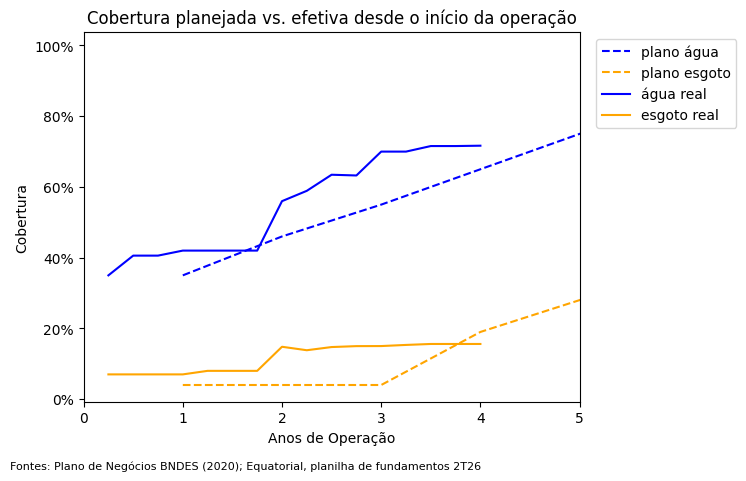

In [29]:
cobertura = op.loc[["Índice de Cobertura (%)", "Índice de cobertura (%)"], "3T22":"2T26"].T
cobertura.columns = ["água", "esgoto"]
cobertura["ano_operacao"] = np.arange(1, 17) / 4
plano = pd.DataFrame({
    "ano_operacao": range(1, 12),
    "agua":   [0.35, 0.46, 0.55, 0.65, 0.75, 0.84, 0.92, 0.96, 0.97, 0.98, 0.99],
    "esgoto": [0.04, 0.04, 0.04, 0.19, 0.28, 0.36, 0.46, 0.52, 0.58, 0.63, 0.68],
})
plt.plot("ano_operacao", "agua", data=plano, label="plano água", linestyle="--", color="blue")
plt.plot("ano_operacao", "esgoto", data=plano, label="plano esgoto", linestyle="--", color="orange")
plt.plot("ano_operacao", "água", data=cobertura, label="água real", color="blue")
plt.plot("ano_operacao", "esgoto", data=cobertura, label="esgoto real", color="orange")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xlim(0, 5)
plt.title("Cobertura planejada vs. efetiva desde o início da operação")
plt.xlabel("Anos de Operação")
plt.ylabel("Cobertura")
plt.figtext(0.01, -0.03, "Fontes: Plano de Negócios BNDES (2020); Equatorial, planilha de fundamentos 2T26", fontsize=8)
plt.gca().yaxis.set_major_formatter(PercentFormatter(1))
plt.savefig("cobertura_plano_vs_real.png", dpi=150, bbox_inches="tight")
plt.show()

**Principais achados:**

- **Água:** a cobertura esteve acima do plano desde o início da operação, mas está estagnada em cerca de 72% desde o ano 3, enquanto o plano prevê universalização (99%) até o ano 11. Além disso, como mostra a seção 3.3, a base de clientes não acompanhou a expansão da rede.
- **Esgoto:** a CSA saiu à frente enquanto o plano previa pouco avanço nos primeiros anos, mas a cobertura está parada em 15-16% há dois anos e ficou abaixo do plano a partir do ano 4, quando a meta começa a acelerar.
- **Investimento:** o esgoto concentra R\$ 2,2 bilhões dos R\$ 3 bilhões de capex previstos, o que significa que a parte mais cara da concessão ainda está por fazer.

**Um comprador da CSA herda a obrigação de financiar a expansão do esgoto numa empresa com patrimônio líquido negativo e R\$ 1,4 bilhão de dívida: o preço de aquisição precisa refletir esse investimento à frente.**

## 3. Premissas

### 3.1 Premissas documentadas

As premissas foram extraídas do contrato de concessão, do Plano de Negócios referencial do BNDES e da planilha de fundamentos do 2T26, publicada pela Equatorial. Cada uma está registrada com fonte e página em `dados/premissas_csa.xlsx`, e o modelo lê todos os valores dessa planilha: nenhuma premissa é digitada no código, de modo que alterar uma premissa exige mudar apenas uma célula.

Nem todas carregam o mesmo peso: algumas vêm de documentos (contrato e plano), outras de dados reais (a calibração da seção 3.2), e algumas são escolhas de modelagem, como adotar o piso da faixa de retorno divulgada pela Kinea (IPCA + 15%) ou o crescimento de 0,85% a.a. no número de economias.

In [30]:
tab_premissas = pd.read_excel(URL_DADOS + "premissas_csa.xlsx", sheet_name="premissas")
tab_premissas["premissa"] = tab_premissas["premissa"].str.strip()   # remove espaços e TABs invisíveis
p = tab_premissas.set_index("premissa")["valor"]
tab_premissas[["premissa", "valor", "unidade", "fonte"]]

,premissa,valor,unidade,fonte
0,prazo_concessao,3.500000e+01,anos,"Plano de Negócios BNDES (PwC, set/2020)"
1,ano_inicio,2.021000e+03,ano,"Plano de Negócios BNDES (PwC, set/2020)"
2,numero_municipios,1.600000e+01,municípios,"Ministério das Cidades, ficha do projeto"
3,outorga_referencial,5.000000e+07,R$,"Plano de Negócios BNDES (PwC, set/2020)"
4,outorga_paga,9.300000e+08,R$,ConectAmapá (notícia)
...,...,...,...,...
70,taxa_urbanizacao,8.977000e-01,% da população,"IBGE, Censo 2010, SIDRA Tabela 202"
71,adesao_final,7.000000e-01,%,Premissa própria
72,ano_adesao_final,2.040000e+03,ano,Premissa própria
73,participacao_equatorial,8.000000e-01,%,"Diário do Amapá (28/05/2025), confirmar em fon..."


### 3.2 Calibração
Antes de projetar o futuro, o modelo é calibrado com o desempenho efetivo da CSA nos últimos doze meses (3T25 a 2T26), a partir da planilha de fundamentos da Equatorial (2T26). São estimadas três grandezas: a tarifa média efetiva por m³, o consumo médio por economia e o opex por economia.

In [31]:
ANO = slice("3T25", "2T26")   # últimos 12 meses (LTM)

# Receita de serviço (R$ mil): só água e esgoto, sem a receita de construção
receita = dre.loc["Receita abastecimento de água e serviço de esgoto", ANO].sum()

# Volume faturado (mil m³): o nome se repete; 1ª linha = água, 2ª = esgoto
vol = op.loc["Volume Faturado (mil m3)", ANO]
volume_agua = vol.iloc[0].sum()
volume_esgoto = vol.iloc[1].sum()
volume_total = volume_agua + volume_esgoto

# Economias (mil): média dos 4 trimestres; 1ª linha = água, 2ª = esgoto
economias_agua = op.loc["Economias ativas (mil)", ANO].iloc[0].mean()
economias_esgoto = op.loc["Economias ativas (mil)", ANO].iloc[1].mean()

# Calibração
tarifa_media_efetiva = receita / volume_total                    # R$/m³
consumo_por_economia = volume_agua / economias_agua / 12         # m³/mês
custos = ["Pessoal", "Material", "Serviço de terceiros", "Outros"]
opex_ltm = -dre.loc[custos, ANO].sum().sum()                     # R$ mil; o sinal de menos deixa positivo
opex_por_economia = opex_ltm / (economias_agua + economias_esgoto)   # R$/ano

print(f"Receita de serviço (LTM): R$ {receita / 1000:.1f} milhões")
print(f"Volume faturado (LTM): {volume_total / 1000:.1f} milhões de m³ "
      f"({volume_agua / 1000:.1f} de água e {volume_esgoto / 1000:.1f} de esgoto)")
print(f"Economias de água (média LTM): {economias_agua:.1f} mil")
print(f"Tarifa média efetiva: R$ {tarifa_media_efetiva:.2f}/m³")
print(f"Consumo por economia: {consumo_por_economia:.1f} m³/mês")
print(f"Opex por economia: R$ {opex_por_economia:,.0f}/ano")
# parcela fixa do opex: pessoal integral + metade de serviços de terceiros e outros (premissa própria)
op_ltm = -dre.loc[custos, ANO].sum(axis=1)          # opex de cada categoria no LTM
parcela_opex_fixa = (op_ltm["Pessoal"] + 0.5 * (op_ltm["Serviço de terceiros"] + op_ltm["Outros"])) / op_ltm.sum()
print(f"Parcela fixa do opex: {parcela_opex_fixa:.0%}")

Receita de serviço (LTM): R$ 119.5 milhões
Volume faturado (LTM): 25.7 milhões de m³ (21.3 de água e 4.4 de esgoto)
Economias de água (média LTM): 95.7 mil
Tarifa média efetiva: R$ 4.65/m³
Consumo por economia: 18.5 m³/mês
Opex por economia: R$ 613/ano
Parcela fixa do opex: 58%


**Resultados (últimos doze meses, 3T25 a 2T26):**

- Tarifa média efetiva: R\$ 4,65/m³ (receita de R\$ 119,5 milhões sobre 25,7 milhões de m³ faturados de água e esgoto)
- Consumo médio: 18,5 m³/mês por economia de água, acima dos 15,5 m³/mês previstos no Plano de Negócios do BNDES
- Opex: R\$ 613 por economia ao ano (pessoal, material, serviços de terceiros e outros)

A tarifa média é cerca de 12% maior que a de 2025 (R\$ 4,16/m³). Parte da alta se explica pelo reajuste anual de 6,52% (calculado a partir da planilha de fundamentos da Equatorial, 2T26). O restante pode refletir mudanças no mix de clientes (mais economias com esgoto, cobrado à parte) ou na estrutura tarifária, mas não foi possível isolar a causa com os dados públicos. Por isso, a tarifa também é testada na análise de sensibilidade.

Uma hipótese para o consumo acima do plano seria a cobrança por volume estimado (cota de 25 m³/mês para economias sem hidrômetro). Os dados, porém, indicam que a micromedição está avançada: foram instalados 81,6 mil hidrômetros entre 2022 e 2026, frente a cerca de 87 mil ligações estimadas. A diferença parece refletir consumo efetivamente medido, o que sugere que o plano foi conservador nesta premissa, em linha com a observação do próprio plano de que o clima do Amapá eleva o consumo.

Ressalvas: parte das instalações pode ser substituição de hidrômetros antigos, e o número atual de ligações é estimado, pois a série deixou de ser divulgada em 2024.

**O modelo adota 18,5 m³/mês como caso base, e os 15,5 m³/mês do plano como cenário pessimista na análise de sensibilidade.**

### 3.3 Universo, cobertura e adesão

O índice de cobertura divulgado pela CSA não mede quantos domicílios são clientes. Pelo contrato de concessão (Anexo III), ele é a razão entre as economias **em condições de serem ligadas** à rede e o total de economias da área de concessão. Ou seja, mede onde a rede chegou, não quem se conectou. Por isso, o modelo separa três componentes:

**economias ativas = universo × cobertura × adesão**

- **Universo:** estimado a partir da população, e não das economias atendidas. A população do Amapá em 2026 (809,9 mil habitantes, IBGE), multiplicada pela taxa de urbanização (89,8%, Censo 2010), já que a concessão abrange as zonas urbanas, dividida por 3,4 habitantes por domicílio e pela participação residencial nas economias (89%), ambas do Plano de Negócios do BNDES. O resultado é de **cerca de 240 mil economias**, próximo das ~261 mil implícitas no plano. A diferença se explica pela estimativa populacional mais alta usada em 2020 e pelo recorte só das sedes urbanas no plano.
- **Adesão:** com cobertura de 71,7%, cerca de 172 mil economias têm rede disponível, mas só 93 mil são clientes ativos. A adesão é de **54%**, abaixo dos 65% com que o plano do BNDES iniciava a concessão e dos 80% que ele esperava após dois anos. No esgoto, a adesão é semelhante (51%), o que sustenta a premissa do plano de adesão igual para os dois serviços.

O histórico mostra que essa diferença está aumentando. Entre o 3T22 e o 2T26, a cobertura de água dobrou (de 35% para 71,7%), mas as economias ativas cresceram só 30% (de 71,6 mil para 93,4 mil). Apenas cerca de **1 em cada 4 domicílios** que ganharam acesso à rede passaram a pagar pelo serviço. Parte do salto da cobertura pode refletir o recadastramento previsto em contrato, e não só obras novas, mas a direção é clara: a rede cresceu muito mais rápido do que a base de clientes.

Há um sinal ainda mais preocupante: as economias ativas de água atingiram o pico no 2T25 (99,6 mil) e caíram por quatro trimestres seguidos, até 93,4 mil no 2T26 (−6%), mesmo com a cobertura subindo. Os dados públicos não permitem identificar a causa (corte de inadimplentes, revisão cadastral ou perda de clientes).

**O desafio do turnaround não é só de engenharia, mas comercial: construir a rede não basta, é preciso converter domicílios com acesso em clientes pagantes.**

In [32]:
# universo de economias: população urbana ÷ participação residencial ÷ habitantes por domicílio
universo_0 = p["populacao_2026"] * p["taxa_urbanizacao"] / p["participacao_residencial"] / p["habitantes_por_domicilio"]

# adesão inicial: dos que têm rede na porta hoje, quantos se ligaram
factiveis_agua_0 = universo_0 * p["cobertura_agua_2T26"]
adesao_inicial = p["economias_agua_2T26"] / factiveis_agua_0

# prova real: a adesão do esgoto é parecida?
factiveis_esgoto_0 = universo_0 * p["cobertura_esgoto_2T26"]
adesao_esgoto_0 = p["economias_esgoto_2T26"] / factiveis_esgoto_0

print(f"Universo hoje: {universo_0:,.0f} economias")
print(f"Água:   {factiveis_agua_0:,.0f} factíveis | adesão {adesao_inicial:.1%}")
print(f"Esgoto: {factiveis_esgoto_0:,.0f} factíveis | adesão {adesao_esgoto_0:.1%}")

# histórico: a rede cresceu mais rápido que os clientes?
cob_hist = pd.to_numeric(op.loc["Índice de Cobertura (%)", "3T22":"2T26"])
econ_hist = pd.to_numeric(op.loc["Economias ativas (mil)", "3T22":"2T26"].iloc[0])   # linha de água
print(f"\nCobertura de água: {cob_hist.iloc[0]:.1%} (3T22) → {cob_hist.iloc[-1]:.1%} (2T26)")
print(f"Economias ativas:  {econ_hist.iloc[0]:,.1f} mil (3T22) → pico de {econ_hist.max():,.1f} mil ({econ_hist.idxmax()}) → {econ_hist.iloc[-1]:,.1f} mil (2T26)")

Universo hoje: 240,282 economias
Água:   172,186 factíveis | adesão 54.3%
Esgoto: 37,484 factíveis | adesão 50.5%

Cobertura de água: 35.0% (3T22) → 71.7% (2T26)
Economias ativas:  71.6 mil (3T22) → pico de 99.6 mil (2T25) → 93.4 mil (2T26)


## 4. Projeção
A projeção cobre de 2027 a 2056, até o fim da concessão de 35 anos iniciada em meados de 2022. Para simplificar, são usados anos-calendário inteiros.

Todos os valores estão em **reais constantes**, sem inflação: a tarifa e os custos de hoje valem para todo o horizonte. Por consistência, o fluxo de caixa será descontado a uma taxa **real** (seção 5).

A projeção é construída em quatro etapas: demanda e receita (4.1), custos e impostos (4.2), investimentos (4.3) e fluxo de caixa livre (4.4).

### 4.1 Demanda e Receita

A receita é projetada a partir de quatro componentes:

- **Universo de economias:** parte das ~240 mil economias estimadas na seção 3.3 e cresce 0,85% ao ano (crescimento vegetativo do Plano de Negócios do BNDES).
- **Cobertura:** cresce linearmente até as metas contratuais (99% de água em 2033 e 90% de esgoto em 2040) e se mantém constante a partir daí. Por ser obrigação contratual, sujeita a penalidades, a cobertura segue o contrato em todos os cenários.
- **Adesão:** parte de 54% e cresce linearmente até **70% em 2040**, no cenário base. O plano do BNDES assume 85% já em 2033, mas o histórico recente mostra a adesão caindo, não subindo. O cenário base supõe uma melhora gradual da gestão comercial, e a premissa do plano fica como cenário otimista na seção 6.
- **Volume e tarifa:** cada economia ativa fatura o consumo calibrado na seção 3.2 (18,5 m³/mês) à tarifa média efetiva de R\$ 4,65/m³.

Simplificações:
- Cada economia com esgoto fatura o mesmo volume que consome de água, aproximação comum já que a tarifa de esgoto é cobrada sobre o volume de água.
- A adesão é a mesma para água e esgoto, premissa também adotada no plano do BNDES e compatível com a adesão atual dos dois serviços (seção 3.3).

In [33]:
proj = pd.DataFrame({"ano": range(2027, 2057)})
t = proj["ano"] - 2026          # anos desde o último dado real

proj["universo"] = universo_0 * (1 + p["crescimento_economias"]) ** t

# cobertura: sobe em linha reta até a meta e depois para
passo_agua = (p["meta_agua"] - p["cobertura_agua_2T26"]) / (p["ano_meta_agua"] - 2026)
proj["cob_agua"] = np.minimum(p["meta_agua"], p["cobertura_agua_2T26"] + passo_agua * t)
passo_esgoto = (p["meta_esgoto"] - p["cobertura_esgoto_2T26"]) / (p["ano_meta_esgoto"] - 2026)
proj["cob_esgoto"] = np.minimum(p["meta_esgoto"], p["cobertura_esgoto_2T26"] + passo_esgoto * t)

# adesão: mesma lógica da cobertura
passo_adesao = (p["adesao_final"] - adesao_inicial) / (p["ano_adesao_final"] - 2026)
proj["adesao"] = np.minimum(p["adesao_final"], adesao_inicial + passo_adesao * t)

# economias ativas = universo × cobertura × adesão
proj["econ_agua"] = proj["universo"] * proj["cob_agua"] * proj["adesao"]
proj["econ_esgoto"] = proj["universo"] * proj["cob_esgoto"] * proj["adesao"]

# volume e receita
proj["volume"] = (proj["econ_agua"] + proj["econ_esgoto"]) * consumo_por_economia * 12
proj["receita"] = proj["volume"] * tarifa_media_efetiva

formatos = {
    "universo":    "{:,.0f}",
    "cob_agua":    "{:.1%}",
    "cob_esgoto":  "{:.1%}",
    "adesao":      "{:.1%}",
    "econ_agua":   "{:,.0f}",
    "econ_esgoto": "{:,.0f}",
    "volume":      lambda x: f"{x / 1e6:,.1f} mi m³",
    "receita":     lambda x: f"R$ {x / 1e6:,.1f} mi",
}
display(proj.style.format(formatos).hide(axis="index"))

ano,universo,cob_agua,cob_esgoto,adesao,econ_agua,econ_esgoto,volume,receita
2027,"242,325",75.6%,20.9%,55.4%,"101,401","28,065",28.8 mi m³,R$ 134.1 mi
2028,"244,385",79.5%,26.2%,56.5%,"109,733","36,216",32.5 mi m³,R$ 151.1 mi
2029,"246,462",83.4%,31.5%,57.6%,"118,416","44,799",36.3 mi m³,R$ 169.0 mi
2030,"248,557",87.3%,36.9%,58.8%,"127,457","53,822",40.3 mi m³,R$ 187.7 mi
2031,"250,670",91.2%,42.2%,59.9%,"136,864","63,295",44.5 mi m³,R$ 207.3 mi
2032,"252,800",95.1%,47.5%,61.0%,"146,644","73,227",48.9 mi m³,R$ 227.7 mi
2033,"254,949",99.0%,52.8%,62.1%,"156,804","83,629",53.5 mi m³,R$ 249.0 mi
2034,"257,116",99.0%,58.1%,63.3%,"161,000","94,509",56.9 mi m³,R$ 264.6 mi
2035,"259,302",99.0%,63.4%,64.4%,"165,257","105,879",60.3 mi m³,R$ 280.8 mi
2036,"261,506",99.0%,68.7%,65.5%,"169,574","117,747",63.9 mi m³,R$ 297.5 mi


In [34]:
# checagem: o crescimento projetado é compatível com o histórico?
anos = 3.75                                                           # do 3T22 ao 2T26
cresc_hist = (econ_hist.iloc[-1] / econ_hist.iloc[0]) ** (1 / anos) - 1
cresc_2027 = proj.loc[0, "econ_agua"] / p["economias_agua_2T26"] - 1
print(f"Crescimento histórico: {cresc_hist:.1%} ao ano")
print(f"Crescimento do modelo em 2027: {cresc_2027:.1%}")

Crescimento histórico: 7.4% ao ano
Crescimento do modelo em 2027: 8.6%


**Checagem:** no cenário base, as economias de água crescem 8,6% em 2027, próximo do crescimento histórico de 7,4% ao ano entre o 3T22 e o 2T26. Com a premissa do plano, o crescimento seria de 15%, o dobro do que a CSA entregou até agora.

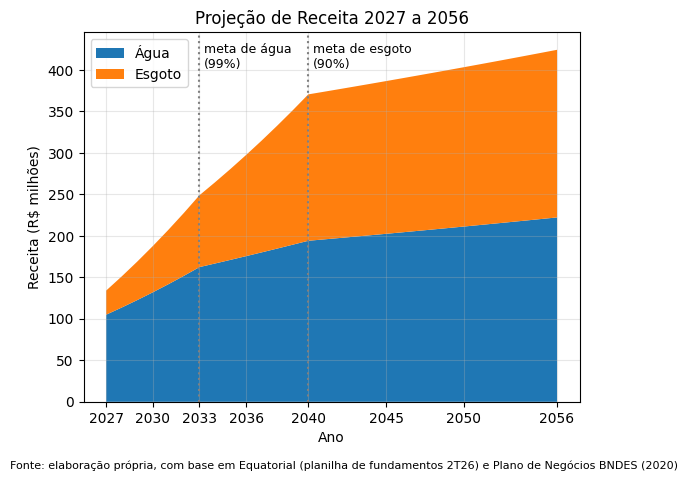

In [35]:
receita_agua = proj["econ_agua"] * consumo_por_economia * 12 * tarifa_media_efetiva / 1e6
receita_esgoto = proj["econ_esgoto"] * consumo_por_economia * 12 * tarifa_media_efetiva / 1e6
topo = proj["receita"].max() / 1e6        # usado para posicionar os rótulos das metas

plt.stackplot(proj["ano"], receita_agua, receita_esgoto, labels=["Água", "Esgoto"], colors=["tab:blue", "tab:orange"])
plt.axvline(p["ano_meta_agua"], color="gray", linestyle=":")
plt.axvline(p["ano_meta_esgoto"], color="gray", linestyle=":")
plt.text(p["ano_meta_agua"] + 0.3, topo * 0.95, f"meta de água\n({p['meta_agua']:.0%})", fontsize=9)
plt.text(p["ano_meta_esgoto"] + 0.3, topo * 0.95, f"meta de esgoto\n({p['meta_esgoto']:.0%})", fontsize=9)
plt.title("Projeção de Receita 2027 a 2056")
plt.xlabel("Ano")
plt.ylabel("Receita (R$ milhões)")
plt.xticks([2027, 2030, 2033, 2036, 2040, 2045, 2050, 2056])
plt.grid(alpha=0.3)
plt.legend(loc="upper left")
plt.figtext(0.01, -0.03, "Fonte: elaboração própria, com base em Equatorial (planilha de fundamentos 2T26) "
            "e Plano de Negócios BNDES (2020)", fontsize=8)
plt.savefig("receita_projetada.png", dpi=150, bbox_inches="tight")
plt.show()

A receita passa de R\$ 134,1 milhões em 2027 para R\$ 424,4 milhões em 2056, em três fases:

- **2027–2033:** crescimento forte, com a expansão simultânea das redes de água e esgoto e o aumento gradual da adesão.
- **2033–2040:** com a água universalizada, o crescimento passa a depender da expansão do esgoto e do aumento da adesão.
- **2040–2056:** com as metas atingidas e a adesão estabilizada em 70%, resta apenas o crescimento vegetativo de 0,85% ao ano, e a CSA se torna um negócio maduro.

**O crescimento das duas primeiras fases depende de investimento: cada ponto de cobertura exige expansão de rede. A seção 4.3 estima quanto custa esse crescimento.**

### 4.2 Custos e Impostos

O EBITDA é a receita menos três itens:

- **Deduções:** PIS e COFINS (9,25% da receita), conforme o Plano de Negócios do BNDES.
- **Inadimplência:** parte de 18,8% da receita (provisões sobre receita no 1S26) e cai linearmente até 10% em 2037, nível do plano do BNDES.
- **Opex:** dividido em duas partes, a partir do opex dos últimos doze meses (R\$ 613 por economia ao ano, seção 3.2):
  - **Custo da rede (58%):** pessoal, mais metade dos serviços de terceiros e de outros custos. Não depende do número de clientes, mas cresce na mesma proporção da rede construída (economias com rede disponível), porque operar mais rede e mais estações de tratamento exige mais equipe e manutenção.
  - **Custo dos clientes (42%):** cresce com as economias ativas, como leitura, cobrança e materiais.

In [36]:
proj["deducoes"] = proj["receita"] * (p["pis"] + p["cofins"])

# inadimplência: cai em linha reta até o piso e depois para (np.maximum = piso)
passo_inad = (p["inadimplencia_final"] - p["inadimplencia_inicial"]) / (p["ano_inadimplencia_final"] - 2026)
proj["taxa_inad"] = np.maximum(p["inadimplencia_final"], p["inadimplencia_inicial"] + passo_inad * t)
proj["inadimplencia"] = proj["receita"] * proj["taxa_inad"]

# opex: parte fixa (não muda com o número de clientes) + parte variável (por economia)
opex_variavel_unit = (1 - parcela_opex_fixa) * opex_por_economia   # R$ por economia/ano
# opex: custo da rede (cresce com a rede construída) + custo dos clientes (cresce com as economias ativas)
opex_fixo_0 = parcela_opex_fixa * opex_ltm * 1000                    # R$/ano hoje (opex_ltm está em R$ mil)
rede_0 = factiveis_agua_0 + factiveis_esgoto_0                       # rede de hoje
rede = proj["universo"] * (proj["cob_agua"] + proj["cob_esgoto"])    # rede de cada ano
opex_variavel_unit = (1 - parcela_opex_fixa) * opex_por_economia
proj["opex"] = opex_fixo_0 * rede / rede_0 + opex_variavel_unit * (proj["econ_agua"] + proj["econ_esgoto"])
proj["ebitda"] = proj["receita"] - proj["deducoes"] - proj["inadimplencia"] - proj["opex"]
proj["margem_ebitda"] = proj["ebitda"] / (proj["receita"] - proj["deducoes"])

formatos.update({
    "deducoes":      lambda x: f"R$ {x / 1e6:,.1f} mi",
    "taxa_inad":     "{:.1%}",
    "inadimplencia": lambda x: f"R$ {x / 1e6:,.1f} mi",
    "opex":          lambda x: f"R$ {x / 1e6:,.1f} mi",
    "ebitda":        lambda x: f"R$ {x / 1e6:,.1f} mi",
    "margem_ebitda": "{:.1%}",
})
colunas_custos = ["ano", "receita", "deducoes", "taxa_inad", "inadimplencia", "opex", "ebitda", "margem_ebitda"]
proj[colunas_custos].style.format(formatos).hide(axis="index")

ano,receita,deducoes,taxa_inad,inadimplencia,opex,ebitda,margem_ebitda
2027,R$ 134.1 mi,R$ 12.4 mi,18.0%,R$ 24.1 mi,R$ 78.8 mi,R$ 18.7 mi,15.4%
2028,R$ 151.1 mi,R$ 14.0 mi,17.2%,R$ 26.0 mi,R$ 87.8 mi,R$ 23.3 mi,17.0%
2029,R$ 169.0 mi,R$ 15.6 mi,16.4%,R$ 27.7 mi,R$ 97.1 mi,R$ 28.5 mi,18.6%
2030,R$ 187.7 mi,R$ 17.4 mi,15.6%,R$ 29.3 mi,R$ 106.7 mi,R$ 34.4 mi,20.2%
2031,R$ 207.3 mi,R$ 19.2 mi,14.8%,R$ 30.7 mi,R$ 116.6 mi,R$ 40.8 mi,21.7%
2032,R$ 227.7 mi,R$ 21.1 mi,14.0%,R$ 31.9 mi,R$ 126.7 mi,R$ 48.0 mi,23.2%
2033,R$ 249.0 mi,R$ 23.0 mi,13.2%,R$ 32.9 mi,R$ 137.2 mi,R$ 55.9 mi,24.7%
2034,R$ 264.6 mi,R$ 24.5 mi,12.4%,R$ 32.8 mi,R$ 144.4 mi,R$ 62.9 mi,26.2%
2035,R$ 280.8 mi,R$ 26.0 mi,11.6%,R$ 32.6 mi,R$ 151.8 mi,R$ 70.5 mi,27.7%
2036,R$ 297.5 mi,R$ 27.5 mi,10.8%,R$ 32.1 mi,R$ 159.3 mi,R$ 78.5 mi,29.1%


A margem EBITDA parte de cerca de 15% em 2027 e sobe até 32% em 2040, estabilizando a partir daí. Duas forças explicam a melhora: a queda da inadimplência, de 18,8% para 10%, e o ganho de escala com a adesão. Como o custo da rede não muda quando mais domicílios se conectam a ela, cada cliente novo dilui esse custo, e o opex por economia ativa cai de cerca de R\$ 610 para R\$ 535.

A separação entre custo da rede e custo dos clientes é uma premissa própria, já que os dados públicos não permitem separá-los. Por isso, a parcela fixa é testada entre 30% e 70% na seção 6.

Mesmo com o ganho de escala, a margem fica muito abaixo dos ~62% previstos no plano do BNDES: o opex por economia continua mais que o dobro do plano (cerca de R\$ 220). A escala sozinha não fecha essa diferença; seria necessário ganho de eficiência, testado como cenário na seção 6.

### 4.3 Investimentos

O capex tem duas partes:

- **Expansão:** cada nova economia **com rede disponível** custa R\$ 2.587 (água) ou R\$ 6.188 (esgoto), valores derivados do Plano de Negócios do BNDES. O capex segue a rede construída (universo × cobertura), e não os clientes que se ligam: a concessionária paga pela obra na rua inteira, mesmo que parte dos moradores não se conecte.
- **Manutenção:** 4% da receita ao ano, conforme o plano.

In [37]:
# rede construída (economias factíveis) = universo × cobertura
proj["fact_agua"] = proj["universo"] * proj["cob_agua"]
proj["fact_esgoto"] = proj["universo"] * proj["cob_esgoto"]

proj["novas_agua"] = np.diff(proj["fact_agua"], prepend=factiveis_agua_0)
proj["novas_esgoto"] = np.diff(proj["fact_esgoto"], prepend=factiveis_esgoto_0)
proj["capex_expansao"] = proj["novas_agua"] * p["capex_por_economia_agua"] + proj["novas_esgoto"] * p["capex_por_economia_esgoto"]
proj["capex_manutencao"] = proj["receita"] * p["capex_manutencao"]
proj["capex"] = proj["capex_expansao"] + proj["capex_manutencao"]

anos_checagem = [2027, 2033, 2034, 2040, 2041]
colunas_capex = ["ano", "novas_agua", "novas_esgoto", "capex_expansao", "capex_manutencao", "capex"]
formatos.update({
    "novas_agua":       "{:,.0f}",
    "novas_esgoto":     "{:,.0f}",
    "capex_expansao":   lambda x: f"R$ {x / 1e6:,.1f} mi",
    "capex_manutencao": lambda x: f"R$ {x / 1e6:,.1f} mi",
    "capex":            lambda x: f"R$ {x / 1e6:,.1f} mi",
})
print(f"Capex de expansão total (2027-2056): R$ {proj['capex_expansao'].sum() / 1e9:,.2f} bilhões")
proj[proj["ano"].isin(anos_checagem)][colunas_capex].style.format(formatos).hide(axis="index")

Capex de expansão total (2027-2056): R$ 1.84 bilhões


ano,novas_agua,novas_esgoto,capex_expansao,capex_manutencao,capex
2027,"10,928","13,196",R$ 109.9 mi,R$ 5.4 mi,R$ 115.3 mi
2033,"12,001","14,569",R$ 121.2 mi,R$ 10.0 mi,R$ 131.2 mi
2034,"2,145","14,808",R$ 97.2 mi,R$ 10.6 mi,R$ 107.8 mi
2040,"2,257","16,307",R$ 106.7 mi,R$ 14.8 mi,R$ 121.6 mi
2041,"2,276","2,069",R$ 18.7 mi,R$ 15.0 mi,R$ 33.6 mi


###4.4 Fluxo de Caixa Livre

In [38]:
# amortização: cada ano de capex é dividido pelos anos que faltam até o fim da concessão
proj["amort_parcela"] = proj["capex"] / (2057 - proj["ano"])
amort_existente = p["capex_realizado_ate_2025"] / (2057 - 2026)     # o que já foi investido até 2025
proj["amortizacao"] = proj["amort_parcela"].cumsum() + amort_existente

# imposto: 34% sobre o EBIT, e só quando há lucro
proj["ebit"] = proj["ebitda"] - proj["amortizacao"]
proj["ir_csll"] = np.maximum(0, proj["ebit"]) * p["ir_csll"]

# fluxo de caixa livre
proj["fcl"] = proj["ebitda"] - proj["ir_csll"] - proj["capex"]

formatos.update({
    "amortizacao": lambda x: f"R$ {x / 1e6:,.1f} mi",
    "ebit":        lambda x: f"R$ {x / 1e6:,.1f} mi",
    "ir_csll":     lambda x: f"R$ {x / 1e6:,.1f} mi",
    "fcl":         lambda x: f"R$ {x / 1e6:,.1f} mi",
})
colunas_fcl = ["ano", "ebitda", "amortizacao", "ebit", "ir_csll", "capex", "fcl"]
proj[colunas_fcl].style.format(formatos).hide(axis="index")

ano,ebitda,amortizacao,ebit,ir_csll,capex,fcl
2027,R$ 18.7 mi,R$ 17.7 mi,R$ 1.0 mi,R$ 0.3 mi,R$ 115.3 mi,R$ -96.9 mi
2028,R$ 23.3 mi,R$ 21.8 mi,R$ 1.5 mi,R$ 0.5 mi,R$ 117.8 mi,R$ -95.0 mi
2029,R$ 28.5 mi,R$ 26.1 mi,R$ 2.4 mi,R$ 0.8 mi,R$ 120.4 mi,R$ -92.7 mi
2030,R$ 34.4 mi,R$ 30.6 mi,R$ 3.7 mi,R$ 1.3 mi,R$ 123.0 mi,R$ -89.9 mi
2031,R$ 40.8 mi,R$ 35.5 mi,R$ 5.4 mi,R$ 1.8 mi,R$ 125.6 mi,R$ -86.6 mi
2032,R$ 48.0 mi,R$ 40.6 mi,R$ 7.4 mi,R$ 2.5 mi,R$ 128.4 mi,R$ -82.9 mi
2033,R$ 55.9 mi,R$ 46.1 mi,R$ 9.8 mi,R$ 3.3 mi,R$ 131.2 mi,R$ -78.6 mi
2034,R$ 62.9 mi,R$ 50.8 mi,R$ 12.2 mi,R$ 4.1 mi,R$ 107.8 mi,R$ -49.0 mi
2035,R$ 70.5 mi,R$ 55.8 mi,R$ 14.7 mi,R$ 5.0 mi,R$ 110.0 mi,R$ -44.5 mi
2036,R$ 78.5 mi,R$ 61.1 mi,R$ 17.4 mi,R$ 5.9 mi,R$ 112.2 mi,R$ -39.6 mi


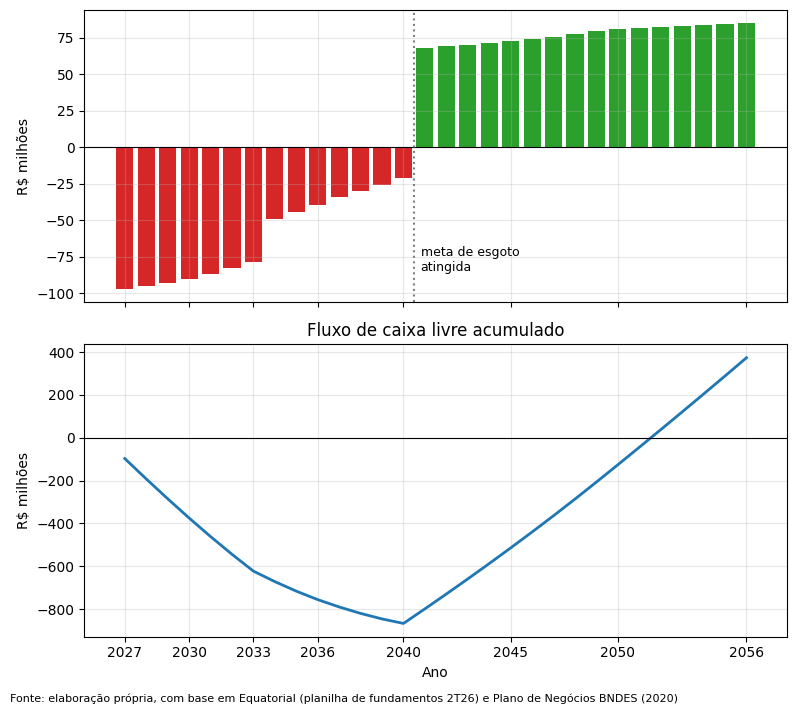

In [39]:
proj["fcl_acumulado"] = proj["fcl"].cumsum()
cores = np.where(proj["fcl"] < 0, "tab:red", "tab:green")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 7), sharex=True)

# em cima: FCL de cada ano
ax1.bar(proj["ano"], proj["fcl"] / 1e6, color=cores)
ax1.axhline(0, color="black", linewidth=0.8)
ax1.axvline(p["ano_meta_esgoto"] + 0.5, color="gray", linestyle=":")
ax1.text(p["ano_meta_esgoto"] + 0.8, ax1.get_ylim()[0] * 0.8, "meta de esgoto\natingida", fontsize=9)
ax1.set_ylabel("R$ milhões")
ax1.grid(alpha=0.3)

# embaixo: FCL acumulado
ax2.plot(proj["ano"], proj["fcl_acumulado"] / 1e6, color="tab:blue", linewidth=2)
ax2.axhline(0, color="black", linewidth=0.8)
ax2.set_title("Fluxo de caixa livre acumulado")
ax2.set_ylabel("R$ milhões")
ax2.set_xlabel("Ano")
ax2.grid(alpha=0.3)

plt.xticks([2027, 2030, 2033, 2036, 2040, 2045, 2050, 2056])
plt.figtext(0.01, -0.01, "Fonte: elaboração própria, com base em Equatorial (planilha de fundamentos 2T26) "
            "e Plano de Negócios BNDES (2020)", fontsize=8)
plt.tight_layout()
plt.savefig("fcl_projetado.png", dpi=150, bbox_inches="tight")
plt.show()

In [40]:
fcl_negativo = proj.loc[proj["fcl"] < 0, "fcl"].sum()
print(f"Soma do FCL negativo (2027-2040): R$ {fcl_negativo / 1e6:,.0f} milhões")
print(f"FCL acumulado em 2056: R$ {proj['fcl_acumulado'].iloc[-1] / 1e6:,.0f} milhões")
fcl_negativo = proj.loc[proj["fcl"] < 0, "fcl"].sum()
fcl_positivo = proj.loc[proj["fcl"] > 0, "fcl"].sum()
ano_payback = proj.loc[proj["fcl_acumulado"] > 0, "ano"].min()
print(f"Soma do FCL negativo: R$ {fcl_negativo / 1e6:,.0f} milhões")
print(f"Soma do FCL positivo: R$ {fcl_positivo / 1e6:,.0f} milhões")
print(f"FCL acumulado em 2056: R$ {proj['fcl_acumulado'].iloc[-1] / 1e6:,.0f} milhões")
print(f"Ano em que o acumulado fica positivo: {ano_payback}")
print(f"IR/CSLL total na concessão: R$ {proj['ir_csll'].sum() / 1e6:,.0f} milhões")

Soma do FCL negativo (2027-2040): R$ -867 milhões
FCL acumulado em 2056: R$ 374 milhões
Soma do FCL negativo: R$ -867 milhões
Soma do FCL positivo: R$ 1,241 milhões
FCL acumulado em 2056: R$ 374 milhões
Ano em que o acumulado fica positivo: 2052
IR/CSLL total na concessão: R$ 91 milhões


O fluxo de caixa livre (FCL) é o EBITDA menos o imposto de renda e a CSLL (34%) e menos o capex. O imposto incide sobre o EBIT, que é o EBITDA menos a amortização dos investimentos. Como os ativos da concessão revertem ao Estado no fim do contrato, cada investimento é amortizado linearmente até 2056.

A curva do FCL tem formato de J: negativa até 2040, melhorando aos poucos, e positiva e crescente a partir de 2041, subindo de R\$ 68 milhões para R\$ 85 milhões em 2056. O salto acontece porque, em 2040, a meta de cobertura de esgoto é atingida, o que zera o capex de expansão e deixa apenas o de manutenção (cerca de R\$ 34 milhões por ano). O crescimento depois de 2041 vem da adesão: com a rede pronta, cada novo cliente dilui o custo da rede.

A CSA paga pouco imposto ao longo da concessão: cerca de R\$ 91 milhões em 30 anos. A amortização é alta durante a maior parte do período, e como o imposto incide sobre o EBIT, que é abatido pela amortização, a base tributável fica pequena.

Entre 2027 e 2040, o FCL negativo soma **R\$ 867 milhões**, que o acionista precisa financiar antes de receber qualquer retorno. De 2041 a 2056, a concessão gera R\$ 1,24 bilhão, e o FCL acumulado só se torna positivo em **2052**, quatro anos antes do fim do contrato. Somando todo o caixa da concessão, o saldo final é de **R\$ 374 milhões**.

**A concessão devolve o caixa que consome, mas devagar e com folga pequena: são 26 anos para recuperar o investimento, e o saldo final equivale a menos de metade do valor investido até 2040. Somado à dívida de R\$ 1,4 bilhão que o comprador herda, esse perfil de caixa é a primeira explicação para a falta de compradores em 2025, como a seção 5 confirma ao considerar o valor do dinheiro no tempo.**

## 5. Valuation

O valor da CSA é estimado pelo fluxo de caixa descontado, em três passos:

1. **Enterprise value (EV):** valor presente dos fluxos de caixa livres de 2027 a 2056, descontados a 15% ao ano em termos reais, o piso da faixa de retorno divulgada pela Kinea (IPCA + 15%). A taxa é real porque o modelo está em reais constantes (seção 4). A data-base é o fim de 2026.
2. **Equity value:** o EV menos a dívida líquida de R\$ 1,41 bilhão (BP da CSA, 2T26), que o comprador herda junto com a empresa.
3. **Fatia à venda:** a participação de 80% da Equatorial (a Aterpa detém os outros 20%).

In [41]:
taxa = p["taxa_real_exigida_kinea"]

# EV: valor presente dos FCLs na data-base (fim de 2026)
ev = npf.npv(taxa, proj["fcl"]) / (1 + taxa)

# equity: o comprador herda a dívida
equity = ev - p["divida_liquida_atual"]
fatia_equatorial = p["participacao_equatorial"]                       # participação à venda (Equatorial 80%, Aterpa 20%)

print(f"Taxa de desconto: {taxa:.0%} real")
print(f"Enterprise value (EV):  R$ {ev / 1e6:,.0f} milhões")
print(f"(−) Dívida líquida:     R$ {p['divida_liquida_atual'] / 1e6:,.0f} milhões")
print(f"(=) Equity value:       R$ {equity / 1e6:,.0f} milhões")
print(f"Fatia da Equatorial (80%): R$ {equity * fatia_equatorial / 1e6:,.0f} milhões")

Taxa de desconto: 15% real
Enterprise value (EV):  R$ -373 milhões
(−) Dívida líquida:     R$ 1,414 milhões
(=) Equity value:       R$ -1,787 milhões
Fatia da Equatorial (80%): R$ -1,429 milhões


No cenário base, a operação da CSA vale **−R\$ 373 milhões**: o valor presente do caixa gerado depois de 2040 não compensa o investimento necessário até lá. Descontada a dívida, o equity value é de **−R\$ 1,79 bilhão**, e a fatia de 80% da Equatorial vale **−R\$ 1,43 bilhão**.

Na prática, um equity negativo significa que nenhum comprador racional pagaria um preço positivo pela CSA: para obter o retorno exigido, ele precisaria **receber** recursos para assumir a empresa. Como o acionista tem responsabilidade limitada, o valor da ação não fica abaixo de zero, e o número representa o tamanho do buraco que alguém precisa cobrir. Os candidatos são a própria Equatorial (aportando capital ou assumindo a dívida antes de uma venda), os credores (aceitando um desconto na dívida) ou o poder concedente (por meio de um reequilíbrio econômico-financeiro do contrato, com revisão de tarifa, prazo ou metas).

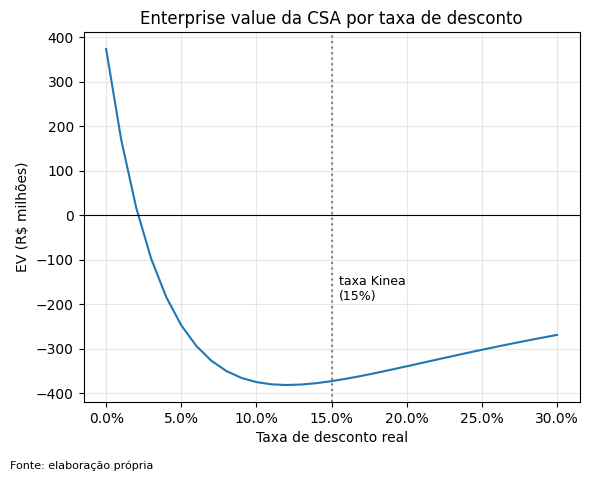

In [42]:
taxas = np.arange(0, 0.31, 0.01)
evs = [npf.npv(r, proj["fcl"]) / (1 + r) / 1e6 for r in taxas]

plt.plot(taxas, evs)
plt.axhline(0, color="black", linewidth=0.8)
plt.axvline(taxa, color="gray", linestyle=":")
plt.text(taxa + 0.005, min(evs) * 0.5, f"taxa Kinea\n({taxa:.0%})", fontsize=9)
plt.gca().xaxis.set_major_formatter(PercentFormatter(1))
plt.title("Enterprise value da CSA por taxa de desconto")
plt.xlabel("Taxa de desconto real")
plt.ylabel("EV (R$ milhões)")
plt.grid(alpha=0.3)
plt.figtext(0.01, -0.03, "Fonte: elaboração própria", fontsize=8)
plt.savefig("ev_por_taxa.png", dpi=150, bbox_inches="tight")
plt.show()

In [43]:
print(f"TIR do projeto: {npf.irr(proj['fcl']):.1%} ao ano real")

TIR do projeto: 2.1% ao ano real


O resultado não depende da taxa de desconto escolhida. A curva só cruza o zero em 2,1% ao ano: essa é a **TIR do projeto**, o retorno real que a concessão entrega a quem financiar todo o investimento. É menos da metade do custo real da dívida da própria CSA (6,8%) e muito abaixo dos 15% exigidos pela Kinea. Na faixa de 7% a 20%, que cobre as taxas usuais para infraestrutura no Brasil, o EV fica sempre entre −R\$ 327 e −R\$ 382 milhões.

O formato da curva tem uma explicação: os fluxos negativos vêm primeiro (2027-2040) e os positivos depois (2041-2056). Com taxas muito baixas, o caixa futuro compensa o investimento, e o EV é positivo. Com taxas intermediárias, o caixa distante é descontado muito mais que o investimento próximo, e o EV atinge o ponto mais baixo (−R\$ 382 milhões, a cerca de 12%). Com taxas altas, até as perdas futuras passam a ser descontadas, e o EV volta a se aproximar de zero, sem cruzá-lo de novo.

**No cenário base, a CSA se paga, mas com retorno de 2,1% ao ano real, abaixo do custo da própria dívida e de qualquer taxa razoável para um investidor de infraestrutura. Isso é consistente com a venda não concluída em 2025: ao preço que um comprador aceitaria pagar, a Equatorial teria de cobrir um prejuízo de mais de R\$ 1,4 bilhão. A pergunta relevante para um investidor de turnaround passa a ser: o que precisa mudar para que o valor se torne positivo? A seção 6 responde.**


##6. Cenários

O cenário base depende de premissas incertas, algumas documentadas (plano e contrato) e outras escolhas de modelagem. Esta seção testa quanto o valor muda quando cada uma varia.

Para isso, o modelo das seções 4 e 5 foi reescrito como uma função, `avaliar()`, que recebe um conjunto de premissas e devolve o EV e o equity value. A função reproduz exatamente o resultado da seção 5 (EV de −R\$ 373 milhões), o que garante que os cenários partem do mesmo modelo.

A análise é feita em duas etapas: primeiro, uma premissa de cada vez, mantendo as demais no cenário base; depois, combinações de premissas em cenários pessimista e otimista.

In [44]:
def linha(inicio, fim, ano_fim, t):
    """Vai em linha reta de 'inicio' até 'fim' em 'ano_fim' e depois fica parado."""
    passo = (fim - inicio) / (ano_fim - 2026)
    valores = inicio + passo * t
    if fim < inicio:                       # caindo (ex.: inadimplência): o fim é um piso
        return np.maximum(fim, valores)
    return np.minimum(fim, valores)        # subindo (ex.: cobertura): o fim é um teto

In [45]:
def avaliar(pr):
    """Roda o modelo completo com as premissas 'pr' e devolve (EV, equity) em R$."""
    d = pd.DataFrame({"ano": range(2027, 2057)})
    t = d["ano"] - 2026

    # 4.1 demanda e receita
    d["universo"] = universo_0 * (1 + pr["crescimento_economias"]) ** t
    d["cob_agua"] = linha(pr["cobertura_agua_2T26"], pr["meta_agua"], pr["ano_meta_agua"], t)
    d["cob_esgoto"] = linha(pr["cobertura_esgoto_2T26"], pr["meta_esgoto"], pr["ano_meta_esgoto"], t)
    d["adesao"] = linha(adesao_inicial, pr["adesao_final"], pr["ano_adesao_final"], t)
    d["econ"] = d["universo"] * (d["cob_agua"] + d["cob_esgoto"]) * d["adesao"]
    d["receita"] = d["econ"] * pr["consumo"] * 12 * pr["tarifa"]

    # 4.2 custos
    d["taxa_inad"] = linha(pr["inadimplencia_inicial"], pr["inadimplencia_final"], pr["ano_inadimplencia_final"], t)
    d["opex_unit"] = linha(pr["opex_unit"], pr["opex_unit_final"], pr["ano_opex_final"], t)
    opex_fixo_0 = pr["parcela_opex_fixa"] * opex_ltm * 1000
    rede = d["universo"] * (d["cob_agua"] + d["cob_esgoto"])
    d["opex"] = (opex_fixo_0 * rede / (factiveis_agua_0 + factiveis_esgoto_0)
                 + (1 - pr["parcela_opex_fixa"]) * d["opex_unit"] * d["econ"])
    d["ebitda"] = d["receita"] * (1 - pr["pis"] - pr["cofins"] - d["taxa_inad"]) - d["opex"]

    # 4.3 capex (segue a rede construída)
    fact_agua = d["universo"] * d["cob_agua"]
    fact_esgoto = d["universo"] * d["cob_esgoto"]
    d["capex"] = (np.diff(fact_agua, prepend=factiveis_agua_0) * pr["capex_por_economia_agua"]
                  + np.diff(fact_esgoto, prepend=factiveis_esgoto_0) * pr["capex_por_economia_esgoto"]
                  + d["receita"] * pr["capex_manutencao"])

    # 4.4 fluxo de caixa livre
    d["amort"] = (d["capex"] / (2057 - d["ano"])).cumsum() + pr["capex_realizado_ate_2025"] / (2057 - 2026)
    d["ir"] = np.maximum(0, d["ebitda"] - d["amort"]) * pr["ir_csll"]
    d["fcl"] = d["ebitda"] - d["ir"] - d["capex"]

    # 5 valuation
    ev = npf.npv(pr["taxa"], d["fcl"]) / (1 + pr["taxa"])
    return ev, ev - pr["divida_liquida_atual"]

In [46]:
pb = p.copy()                                   # cópia: mexer no pb não estraga o p original
pb["consumo"] = consumo_por_economia
pb["tarifa"] = tarifa_media_efetiva
pb["taxa"] = p["taxa_real_exigida_kinea"]
pb["opex_unit"] = opex_por_economia
pb["opex_unit_final"] = opex_por_economia      # base: sem ganho de eficiência
pb["ano_opex_final"] = 2035
pb["parcela_opex_fixa"] = parcela_opex_fixa
ev_base, equity_base = avaliar(pb)
print(f"Cenário base | EV: R$ {ev_base / 1e6:,.0f} mi | Equity: R$ {equity_base / 1e6:,.0f} mi")

Cenário base | EV: R$ -373 mi | Equity: R$ -1,787 mi


In [47]:
cenarios = {
    "Adesão constante em 54%":              {"adesao_final": adesao_inicial},
    "Adesão de 85% em 2033 (plano)":        {"adesao_final": p["adesao_final_plano"],
                                             "ano_adesao_final": p["ano_adesao_final_plano"]},
    "Consumo de 15,5 m³ (plano)":           {"consumo": p["consumo_final"]},
    "Tarifa de 2025 (R$ 4,16)":             {"tarifa": 4.16},
    "Tarifa +10%":                          {"tarifa": tarifa_media_efetiva * 1.10},
        "Eficiência moderada (custo variável −35%)": {"opex_unit_final": opex_por_economia * 0.65},
    "Eficiência forte (custo variável −64%)":    {"opex_unit_final": opex_por_economia * 0.36},
    "Opex 30% fixo":                             {"parcela_opex_fixa": 0.30},
    "Opex 70% fixo":                             {"parcela_opex_fixa": 0.70},
    "Capex unitário −20%":                  {"capex_por_economia_agua": p["capex_por_economia_agua"] * 0.8,
                                             "capex_por_economia_esgoto": p["capex_por_economia_esgoto"] * 0.8},
    "Taxa de desconto de 10%":              {"taxa": 0.10},}

resultados = []
for nome, mudancas in cenarios.items():
    pr = pb.copy()                    # parte sempre do cenário base
    for premissa, valor in mudancas.items():
        pr[premissa] = valor          # aplica só as mudanças desse cenário
    ev, equity = avaliar(pr)
    resultados.append({"cenario": nome, "ev": ev, "equity": equity, "delta_ev": ev - ev_base})

tab_cenarios = pd.DataFrame(resultados).sort_values("delta_ev", ascending=False)
tab_cenarios.style.format({
    "ev":       lambda x: f"R$ {x / 1e6:,.0f} mi",
    "equity":   lambda x: f"R$ {x / 1e6:,.0f} mi",
    "delta_ev": lambda x: f"{x / 1e6:+,.0f} mi",}).hide(axis="index")

cenario,ev,equity,delta_ev
Eficiência forte (custo variável −64%),R$ -255 mi,"R$ -1,668 mi",+119 mi
Capex unitário −20%,R$ -255 mi,"R$ -1,669 mi",+118 mi
Adesão de 85% em 2033 (plano),R$ -257 mi,"R$ -1,670 mi",+116 mi
Tarifa +10%,R$ -298 mi,"R$ -1,711 mi",+75 mi
Eficiência moderada (custo variável −35%),R$ -308 mi,"R$ -1,721 mi",+65 mi
Opex 70% fixo,R$ -363 mi,"R$ -1,777 mi",+10 mi
Taxa de desconto de 10%,R$ -375 mi,"R$ -1,789 mi",-2 mi
Opex 30% fixo,R$ -397 mi,"R$ -1,810 mi",-23 mi
Adesão constante em 54%,R$ -463 mi,"R$ -1,877 mi",-90 mi
"Tarifa de 2025 (R$ 4,16)",R$ -477 mi,"R$ -1,890 mi",-104 mi


In [48]:
combinados = {
    "Pessimista": {**cenarios["Adesão constante em 54%"], **cenarios["Consumo de 15,5 m³ (plano)"],
                   **cenarios["Tarifa de 2025 (R$ 4,16)"]},
    "Base":       {},
    "Otimista":   {**cenarios["Adesão de 85% em 2033 (plano)"], **cenarios["Eficiência moderada (custo variável −35%)"],
                   **cenarios["Capex unitário −20%"], **cenarios["Tarifa +10%"]},}

for nome, mudancas in combinados.items():
    pr = pb.copy()
    for premissa, valor in mudancas.items():
        pr[premissa] = valor
    ev, equity = avaliar(pr)
    desconto_divida = max(0, -equity) / p["divida_liquida_atual"]   # quanto da dívida teria que ser perdoado para o equity valer zero
    print(f"{nome:<11} | EV: R$ {ev / 1e6:>6,.0f} mi | Equity: R$ {equity / 1e6:>7,.0f} mi | "
          f"desconto na dívida para equity = 0: {desconto_divida:.0%}")

Pessimista  | EV: R$   -712 mi | Equity: R$  -2,125 mi | desconto na dívida para equity = 0: 150%
Base        | EV: R$   -373 mi | Equity: R$  -1,787 mi | desconto na dívida para equity = 0: 126%
Otimista    | EV: R$     33 mi | Equity: R$  -1,381 mi | desconto na dívida para equity = 0: 98%


Combinando as premissas:

| Cenário | Premissas | EV | Equity |
|---|---|---|---|
| Pessimista | Adesão constante, consumo de 15,5 m³, tarifa de 2025 | −R\$ 712 mi | −R\$ 2,1 bi |
| Base | Seções 3 e 4 | −R\$ 373 mi | −R\$ 1,8 bi |
| Otimista | Adesão de 85%, eficiência moderada, capex −20%, tarifa +10% | +R\$ 32 mi | −R\$ 1,4 bi |

Mesmo no cenário otimista, com quatro alavancas de turnaround entregues ao mesmo tempo, a operação vale pouco mais que zero. E o equity continua negativo em todos os cenários: a dívida de R\$ 1,41 bilhão é várias vezes maior que o valor que a operação consegue gerar. Para que o equity valesse zero, os credores teriam de abrir mão de 98% da dívida no cenário otimista. Nos cenários base e pessimista, nem o perdão total da dívida bastaria.

**O problema da CSA está menos na operação e mais na estrutura de capital. A operação, no melhor caso, se paga com retorno baixo; a dívida, em nenhum cenário. Um investidor só criaria valor entrando depois de uma reestruturação que reduza a dívida a um nível compatível com a operação, e pagando um preço simbólico pelo equity.**

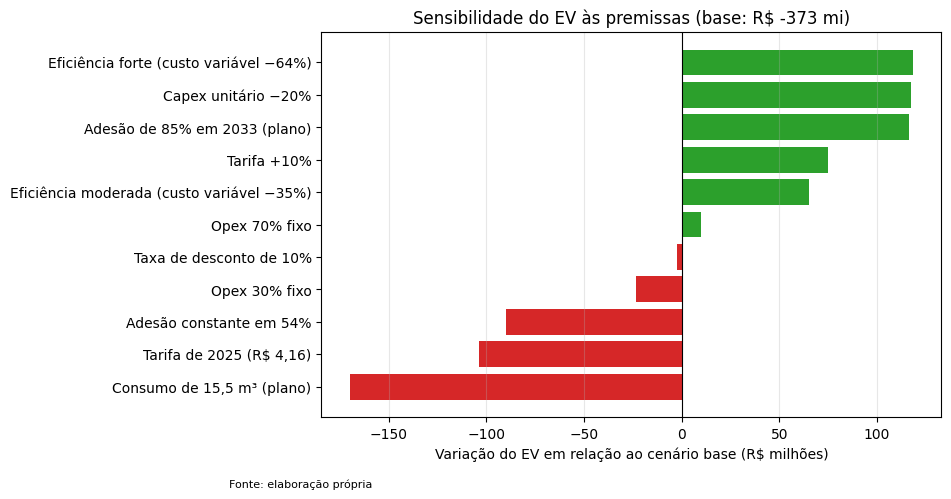

In [49]:
tornado = tab_cenarios.sort_values("delta_ev")             # a maior barra vai para o topo
cores = np.where(tornado["delta_ev"] > 0, "tab:green", "tab:red")

plt.figure(figsize=(8, 5))
plt.barh(tornado["cenario"], tornado["delta_ev"] / 1e6, color=cores)
plt.axvline(0, color="black", linewidth=0.8)
plt.title(f"Sensibilidade do EV às premissas (base: R$ {ev_base / 1e6:,.0f} mi)")
plt.xlabel("Variação do EV em relação ao cenário base (R$ milhões)")
plt.grid(axis="x", alpha=0.3)
plt.figtext(0.01, -0.03, "Fonte: elaboração própria", fontsize=8)
plt.savefig("tornado_cenarios.png", dpi=150, bbox_inches="tight")
plt.show()

As três alavancas positivas de maior efeito têm peso muito parecido, cerca de R\$ 115 milhões cada, e representam frentes diferentes do turnaround:

- **Comercial:** elevar a adesão a 85% até 2033, como previa o plano do BNDES (+R\$ 116 milhões)
- **Operacional:** reduzir o custo variável por economia em 64%, por exemplo com redução de perdas de água, hoje em 67% (+R\$ 119 milhões)
- **Engenharia:** executar as obras com custo unitário 20% menor (+R\$ 118 milhões)

Nenhuma delas, sozinha, torna o EV positivo.

Os maiores riscos negativos vêm de variáveis fora do controle da gestão. O principal é o consumo: se o consumo por economia convergir para os 15,5 m³/mês do plano, o EV cai R\$ 170 milhões. Como a receita é proporcional ao consumo e os custos não caem junto, essa é a premissa mais sensível do modelo, e confirmar a série de consumo medido seria prioridade numa due diligence. A volta da tarifa ao nível de 2025 (−R\$ 104 milhões) e a estagnação da adesão (−R\$ 90 milhões) completam os riscos.

Duas premissas incertas têm pouco efeito. A parcela fixa do opex, testada entre 30% e 70%, muda o EV em menos de R\$ 25 milhões, e a taxa de desconto de 10%, em vez de 15%, praticamente não altera o resultado, como já mostrava a seção 5.

**O padrão é claro: as alavancas que criam valor são de execução, e as que destroem valor são de mercado.**

## 7. Conclusão

A aquisição da CSA por um investidor de situações especiais só se justifica a um preço simbólico (por exemplo, R\$ 1) e mediante uma reestruturação prévia da sua dívida. O problema dominante da concessão está na sua estrutura de capital. A tese de turnaround mapeada por este modelo depende da repactuação do passivo para um nível compatível com a operação, acompanhada da execução simultânea de três alavancas: comercial (adesão e adimplência), operacional (eficiência e redução de perdas) e de engenharia (racionalização do capex), além de um eventual reequilíbrio econômico-financeiro do contrato junto ao poder concedente. As alavancas que criam valor são de execução; as que o destroem, como consumo e tarifa, são de mercado e estão fora do controle do comprador.

Do ponto de vista operacional, o modelo evidencia que a expansão de cobertura mede infraestrutura, não captação de clientes. Conforme os indicadores operacionais da CSA, apenas 54% dos domicílios com rede disponível são clientes ativos, e só um em cada quatro domicílios que ganharam acesso à rede passou a pagar pelo serviço. Além disso, as economias ativas caem desde o segundo trimestre de 2025.

Do ponto de vista financeiro, a concessão só atinge o payback em 2052 e entrega uma TIR real de apenas 2,1%, inferior ao custo da própria dívida (6,8%). Isso resulta em um EV de −R\$ 373 milhões no cenário base, a uma taxa de desconto de 15% real. Mesmo no cenário otimista, com quatro alavancas operacionais combinadas, o equity permanece negativo em −R\$ 1,4 bilhão, o que reforça que ajustes operacionais isolados não resolvem o desequilíbrio da estrutura de capital.

As limitações do modelo giram em torno da parcela fixa do opex e da adesão do cenário base, adotadas como premissas próprias. Como o consumo é a variável de maior sensibilidade, uma due diligence deveria priorizar a série histórica de consumo medido versus estimado, que não está disponível nas fontes públicas. Por fim, sem acesso ao data room (contratos de dívida, garantias e cadastro comercial), permanece uma questão central: a dívida tem garantia corporativa da Equatorial? Se tiver, a responsabilidade de cobrir o déficit recai sobre a garantidora, o que ajudaria a explicar a não conclusão da venda.
**A CSA não é uma compra pela operação, e sim pela reestruturação: como a operação não consegue pagar a dívida em nenhum cenário, o investimento só faz sentido depois de reduzir o passivo e com um plano operacional capaz de entregar adesão, eficiência e capex ao mesmo tempo.**